In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu
import json

sns.set_theme(style="whitegrid")

DATA_PATH = Path("loan_data.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("../loan_data.csv")

df = pd.read_csv(DATA_PATH)

display(df.head())
print("Розмір:", df.shape)
df.info()


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
1,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
2,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
3,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
4,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y


Розмір: (381, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            381 non-null    object 
 1   Gender             376 non-null    object 
 2   Married            381 non-null    object 
 3   Dependents         373 non-null    object 
 4   Education          381 non-null    object 
 5   Self_Employed      360 non-null    object 
 6   ApplicantIncome    381 non-null    int64  
 7   CoapplicantIncome  381 non-null    float64
 8   LoanAmount         381 non-null    float64
 9   Loan_Amount_Term   370 non-null    float64
 10  Credit_History     351 non-null    float64
 11  Property_Area      381 non-null    object 
 12  Loan_Status        381 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 38.8+ KB


На початковому етапі дослідження встановлено, що вихідний набір даних містить 381 спостереження та 13 змінних, які характеризують кредитні заявки інші фактори. Цільовою змінною є Loan_Status, яка визначає факт схвалення або відхилення кредитної заявки. Ідентифікатор Loan_ID не має безпосереднього аналітичного змісту для прогнозування та буде виключений із набору предикторів.
Первинний аналіз виявив пропущені значення у чотирьох змінних: Gender (5), Dependents (8), Self_Employed (21) та Credit_History (30). Найбільша частка пропусків спостерігається у змінній кредитної історії.
Розглянемо детальніше основні статистичні показники даного набору даних.

In [ ]:
display(df.describe(include="all").T)

quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(dropna=True)
})

display(quality)

print("Дублікати повних рядків:", df.duplicated().sum())
print("Дублікати Loan_ID:", df["Loan_ID"].duplicated().sum())

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,381,381,LP001003,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,376,2,Male,291,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,381,2,Yes,228,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,373,4,0,234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,381,2,Graduate,278,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,360,2,No,325,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,381.0,NaN,NaN,NaN,3579.845144,1419.813818,150.0,2600.0,3333.0,4288.0,9703.0
CoapplicantIncome,381.0,NaN,NaN,NaN,1277.275381,2340.818114,0.0,0.0,983.0,2016.0,33837.0
LoanAmount,381.0,NaN,NaN,NaN,104.986877,28.358464,9.0,90.0,110.0,127.0,150.0
Loan_Amount_Term,370.0,NaN,NaN,NaN,340.864865,68.549257,12.0,360.0,360.0,360.0,480.0


,dtype,missing,missing_%,unique
Loan_ID,object,0,0.00,381
Gender,object,5,1.31,2
Married,object,0,0.00,2
Dependents,object,8,2.10,4
Education,object,0,0.00,2
Self_Employed,object,21,5.51,2
ApplicantIncome,int64,0,0.00,322
CoapplicantIncome,float64,0,0.00,182
LoanAmount,float64,0,0.00,101
Loan_Amount_Term,float64,11,2.89,10


Дублікати повних рядків: 0
Дублікати Loan_ID: 0


На основі проведеного аналізу 381 кредитної заявки робимо висновок: середній дохід основного позичальника становить 3579,85, медіанний — 3333. Для доходу співпозичальника характерна значна варіація: середнє значення дорівнює 1277,28, тоді як максимальне досягає 33837. Така відмінність свідчить про можливу наявність викидів, які потребують подальшого дослідження. Середня сума кредиту становить 104,99, медіанна — 110. Для терміну кредитування характерна концентрація значень на рівні 360.
У структурі позичальників переважають чоловіки, особи з вищою освітою, одружені заявники та особи, які не є самозайнятими.
Наступний аналіз присвятимо розподілу цільової змінної - схвалення кредитної позики.

,Кількість,"Частка, %"
Loan_Status,,
Y,271,71.13
N,110,28.87


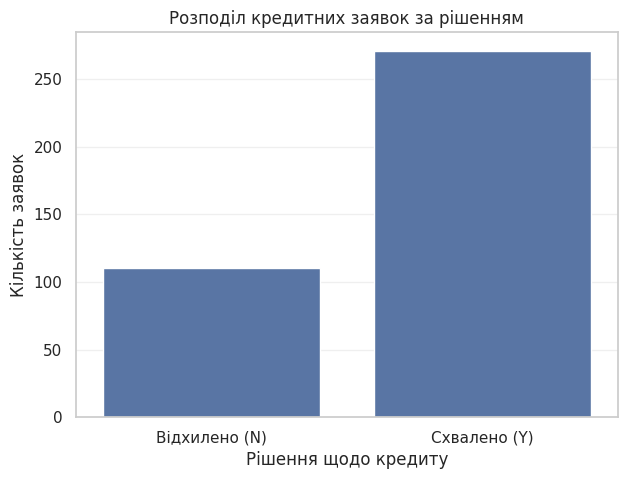

In [ ]:
target_counts = df["Loan_Status"].value_counts()
target_percent = df["Loan_Status"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Кількість": target_counts,
    "Частка, %": target_percent.round(2)
})

display(target_summary)

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Loan_Status",
    order=["N", "Y"]
)

plt.title("Розподіл кредитних заявок за рішенням")
plt.xlabel("Рішення щодо кредиту")
plt.ylabel("Кількість заявок")

ax.set_xticks(
    [0, 1],
    labels=["Відхилено (N)", "Схвалено (Y)"]
)

plt.grid(axis="y", alpha=0.3)
plt.show()


Аналіз розподілу цільової змінної Loan_Status показав, що із 381 кредитної заявки 271 (71,13%) була схвалена, а 110 (28,87%) — відхилені.
Тому у даній вибірці спостерігається дисбаланс класів: кількість схвалених заявок приблизно у 2,46 раза перевищує кількість відхилених.
Далі проаналізуємо пояснюючі числові змінні даної моделі.

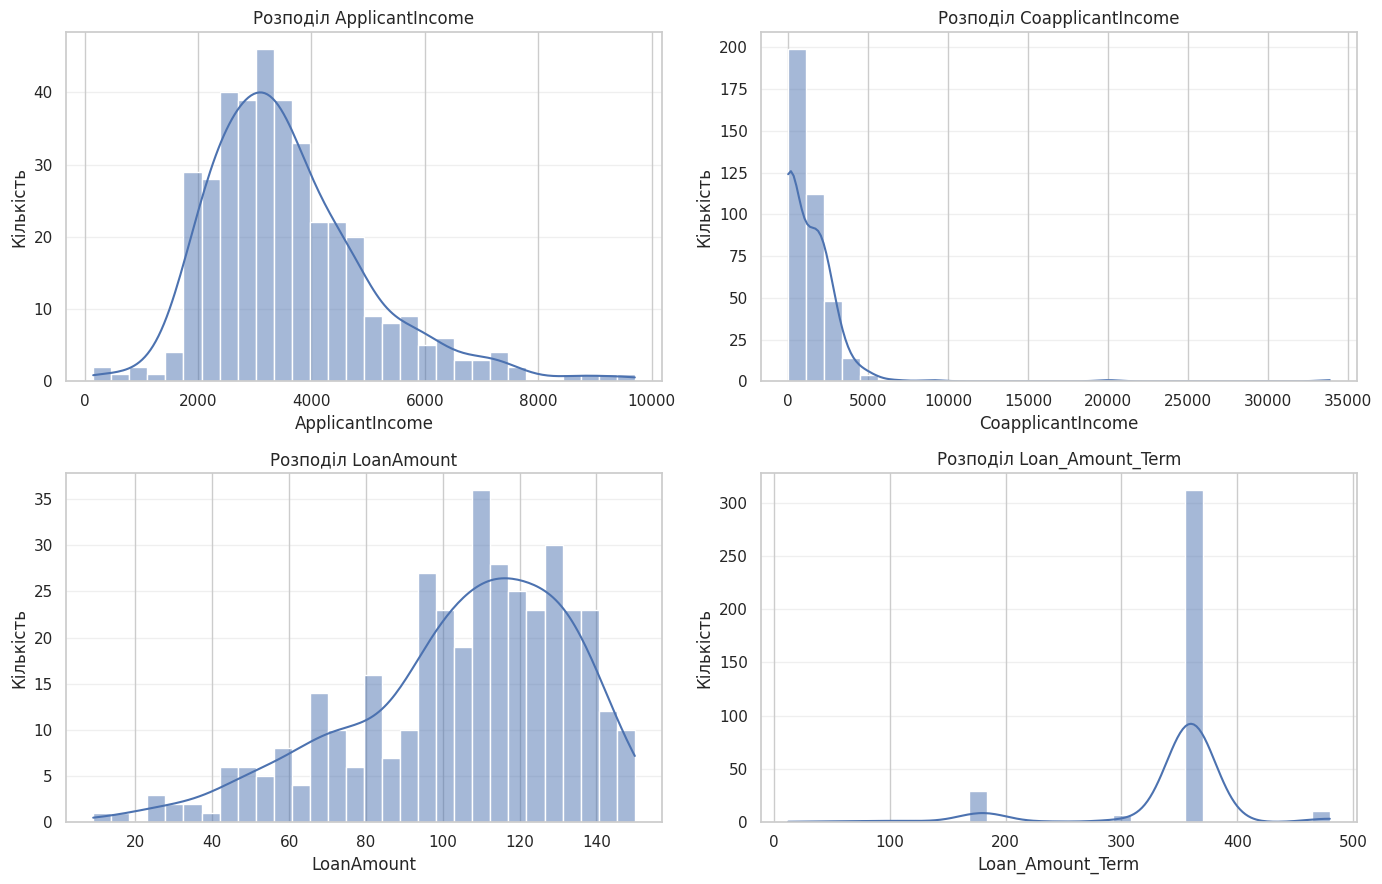

In [ ]:
numeric_columns = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, column in zip(axes.flat, numeric_columns):
    sns.histplot(
        data=df,
        x=column,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Розподіл {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Кількість")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Розподіл доходу основного позичальника (ApplicantIncome) характеризується правосторонньою асиметрією. Основна частина значень зосереджена приблизно в діапазоні 2000–4500, тоді як окремі спостереження досягають 9703.
Для доходу співпозичальника (CoapplicantIncome) характерна виражена правостороння асиметрія. Значна кількість спостережень має нульові або невеликі доходи, проте максимальне значення становить 33837. Це свідчить про наявність потенційних екстремальних значень, які потребують додаткової перевірки.
Розподіл суми кредиту (LoanAmount) характеризується переважанням значень приблизно в діапазоні 95–145 та довшим лівим хвостом. Середня сума кредиту (104,99) є нижчою за медіанну (110), що узгоджується з візуальною лівосторонньою асиметрією.
Розподіл терміну кредитування (Loan_Amount_Term) характеризується значною концентрацією спостережень на рівні 360, тоді як інші терміни зустрічаються значно рідше.
Результати візуального аналізу підтверджують необхідність подальшого дослідження асиметрії та потенційних викидів. Особливу увагу слід приділити змінній CoapplicantIncome, для якої виявлено значне відхилення максимального значення від основної маси спостережень.
Додатково проаналізуємо показники ApplicantIncome, CoapplicantIncome та Loan_Amount_Term за допомогою Boxplot.

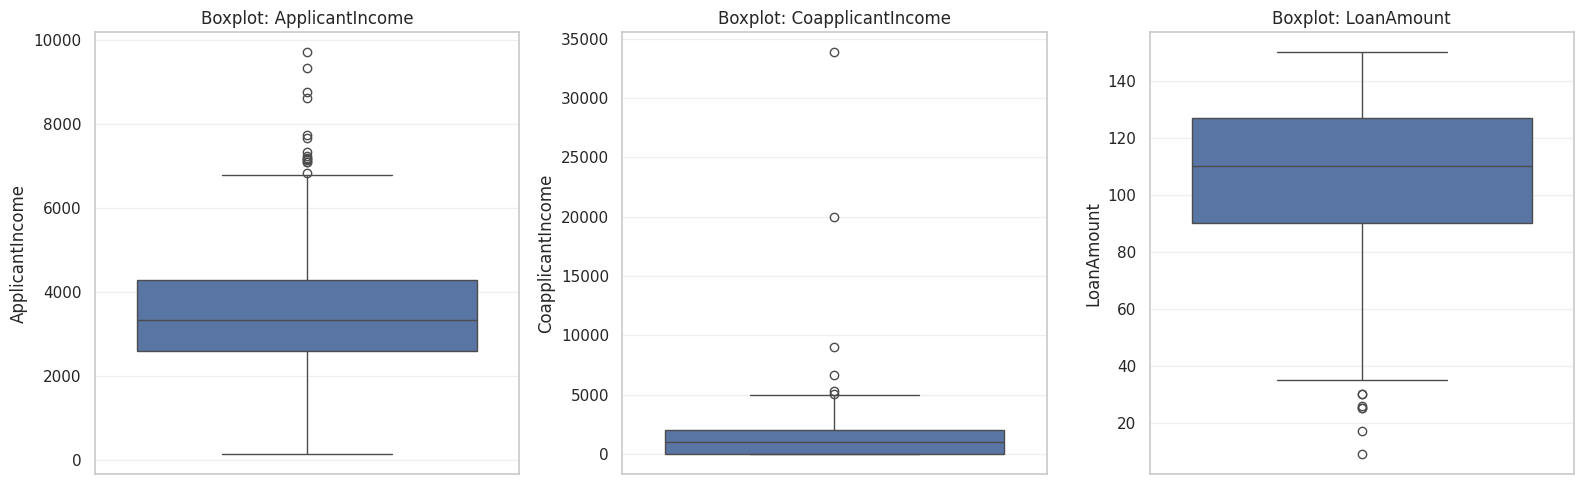

,Змінна,Асиметрія,Q1,Q3,IQR,Нижня межа,Верхня межа,Кількість викидів,"Частка викидів, %"
0,ApplicantIncome,1.120,2600.0,4288.0,1688.0,68.0,6820.0,14,3.67
1,CoapplicantIncome,8.661,0.0,2016.0,2016.0,-3024.0,5040.0,6,1.57
2,LoanAmount,-0.804,90.0,127.0,37.0,34.5,182.5,7,1.84


In [ ]:
columns = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, column in zip(axes, columns):
    sns.boxplot(
        data=df,
        y=column,
        ax=ax
    )

    ax.set_title(f"Boxplot: {column}")
    ax.set_ylabel(column)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

results = []

for column in columns:
    data = df[column].dropna()

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = ((data < lower) | (data > upper)).sum()

    results.append({
        "Змінна": column,
        "Асиметрія": round(data.skew(), 3),
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Нижня межа": round(lower, 2),
        "Верхня межа": round(upper, 2),
        "Кількість викидів": int(outliers),
        "Частка викидів, %": round(
            outliers / len(data) * 100, 2
        )
    })

outliers_df = pd.DataFrame(results)

display(outliers_df)

За результатами аналізу встановлено:
ApplicantIncome: виявлено 14 потенційних викидів (3,67% спостережень). Коефіцієнт асиметрії становить 1,120, що свідчить про правосторонню асиметрію розподілу. Потенційні викиди представлені переважно високими доходами позичальників.
CoapplicantIncome: виявлено 6 потенційних викидів (1,57%). Коефіцієнт асиметрії становить 8,661, що свідчить про надзвичайно виражену правосторонню асиметрію. Окремі значення доходу співпозичальника суттєво перевищують основну масу спостережень.
LoanAmount: виявлено 7 потенційних викидів (1,84%). Коефіцієнт асиметрії становить −0,804, що підтверджує лівосторонню асиметрію. Потенційні викиди відповідають порівняно невеликим сумам кредитів.
Загалом частка потенційних викидів за кожною із досліджуваних змінних не перевищує 4%. Однак навіть невелика кількість екстремальних значень може впливати на статистичні характеристики та результати навчання окремих моделей машинного навчання.
Під час подальшої побудови моделей доцільно розглянути логарифмічне перетворення асиметричних ознак та використання методів масштабування.
Також перевіримо форму розподілу даних кількісних предикторів за критерієм Шапіро–Вілка.

In [ ]:
from scipy.stats import shapiro

alpha = 0.05

numeric_features = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term",
]

normality_results = []

for col in numeric_features:
    values = df[col].dropna()

    statistic, p_value = shapiro(values)

    normality_results.append({
        "Ознака": col,
        "Кількість": len(values),
        "W Шапіро–Вілка": statistic,
        "p-value": p_value,
        "Рішення": (
            "Відхиляємо H0"
            if p_value < alpha
            else "Не відхиляємо H0"
        )
    })

normality_df = pd.DataFrame(normality_results)

display(
    normality_df.style.format({
        "W Шапіро–Вілка": "{:.4f}",
        "p-value": "{:.6g}"
    })
)

,Ознака,Кількість,W Шапіро–Вілка,p-value,Рішення
0,ApplicantIncome,381,0.9347,7.03023e-12,Відхиляємо H0
1,CoapplicantIncome,381,0.4400,9.87103e-33,Відхиляємо H0
2,LoanAmount,381,0.9486,3.05041e-10,Відхиляємо H0
3,Loan_Amount_Term,370,0.5015,6.33736e-31,Відхиляємо H0


За результатами перевірки нормальності розподілу всіх чотирьох числових ознак за критерієм Шапіро–Вілка встановлено, що для всіх досліджуваних змінних значення p-value є меншими за встановлений рівень значущості α = 0,05. Отже, нульову гіпотезу про нормальність розподілу відхилено для кожної ознаки. Перерівримо тепер за критерієм Манна-Уїтні відменності між розподілами числових ознак у випадку схвалення або ж відмови від отримання кредиту.

In [ ]:
from scipy.stats import mannwhitneyu

alpha = 0.05

numeric_features = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term",
]

mw_results = []

for col in numeric_features:
    approved = df.loc[
        df["Loan_Status"] == "Y", col
    ].dropna()

    rejected = df.loc[
        df["Loan_Status"] == "N", col
    ].dropna()

    u_stat, p_value = mannwhitneyu(
        approved,
        rejected,
        alternative="two-sided"
    )

    mw_results.append({
        "Ознака": col,
        "Медіана Y": approved.median(),
        "Медіана N": rejected.median(),
        "U Манна–Уітні": u_stat,
        "p-value": p_value,
        "Рішення": (
            "Відхиляємо H0"
            if p_value < alpha
            else "Не відхиляємо H0"
        )
    })

mw_df = pd.DataFrame(mw_results)

mw_df = mw_df.sort_values("p-value")

display(
    mw_df.style.format({
        "Медіана Y": "{:.3f}",
        "Медіана N": "{:.3f}",
        "U Манна–Уітні": "{:.1f}",
        "p-value": "{:.6g}",
    })
)


,Ознака,Медіана Y,Медіана N,U Манна–Уітні,p-value,Рішення
1,CoapplicantIncome,1210.000,0.000,17157.5,0.0149887,Відхиляємо H0
2,LoanAmount,111.000,106.000,15953.5,0.281898,Не відхиляємо H0
3,Loan_Amount_Term,360.000,360.000,13367.0,0.352783,Не відхиляємо H0
0,ApplicantIncome,3276.000,3418.000,14289.0,0.527488,Не відхиляємо H0


На рівні значущості α = 0,05 статистично значущі відмінності встановлено лише для доходу співзаявника CoapplicantIncome (U = 17157,5; p = 0,01499). Для ApplicantIncome, LoanAmount, Loan_Amount_Term статистично значущих відмінностей між групами не встановлено (p-value > 0,05). Медіани більшості показників у групах схвалених і відхилених кредитів є близькими.
На наступному етапі EDA-аналізу дослідимо категоріальні змінні.

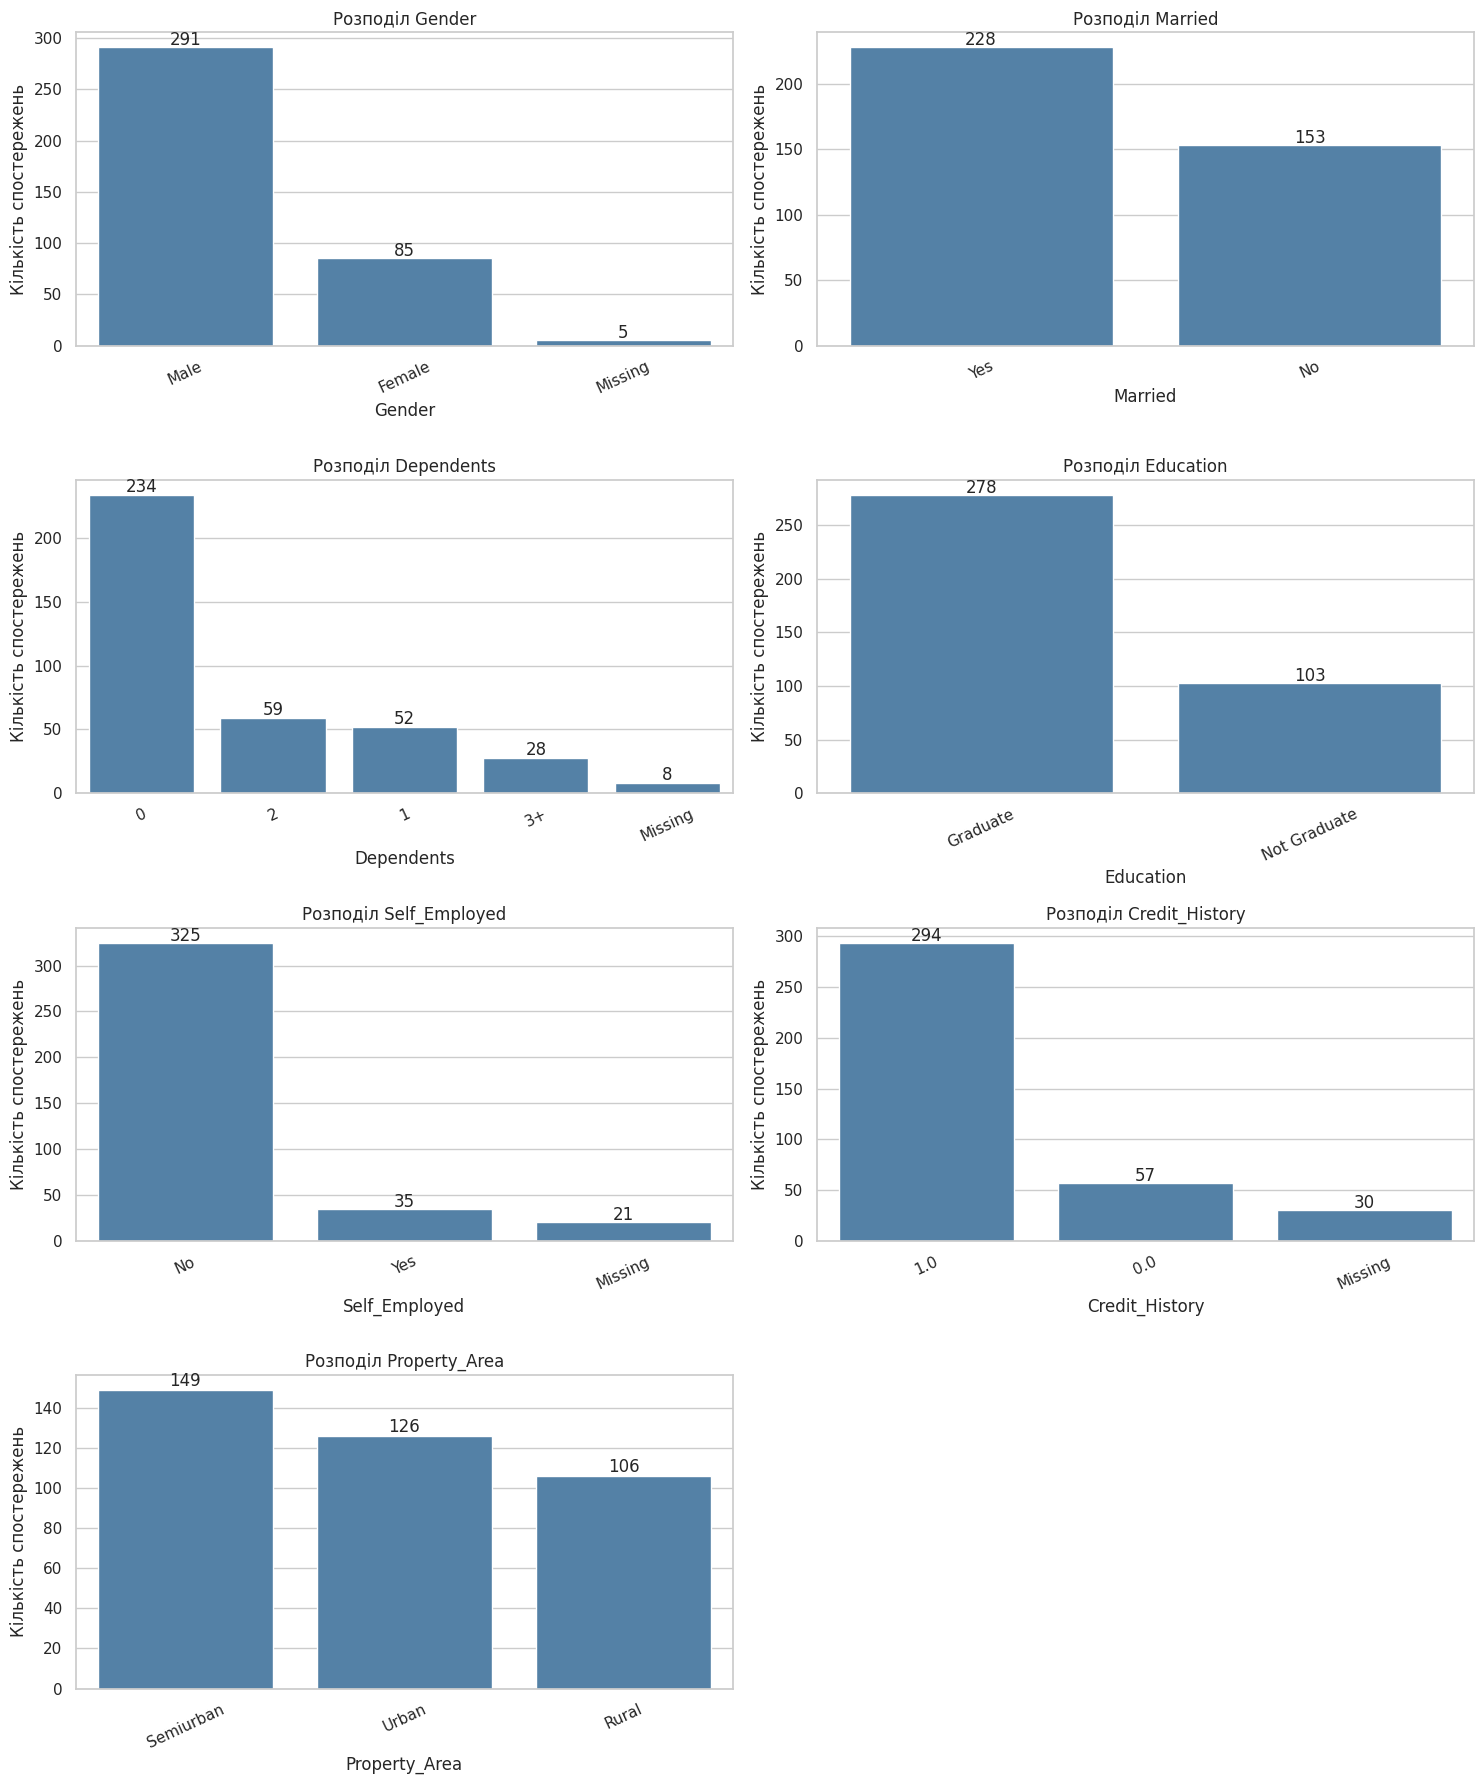


Gender


,Кількість,"Частка, %"
Gender,,
Male,291,76.38
Female,85,22.31
Missing,5,1.31



Married


,Кількість,"Частка, %"
Married,,
Yes,228,59.84
No,153,40.16



Dependents


,Кількість,"Частка, %"
Dependents,,
0,234,61.42
2,59,15.49
1,52,13.65
3+,28,7.35
Missing,8,2.10


... (4 outputs left out)


Credit_History


,Кількість,"Частка, %"
Credit_History,,
1.0,294,77.17
0.0,57,14.96
Missing,30,7.87



Property_Area


,Кількість,"Частка, %"
Property_Area,,
Semiurban,149,39.11
Urban,126,33.07
Rural,106,27.82


In [ ]:
categorical_cols = [
    "Gender",
    "Married",
    "Dependents",
    "Education",
    "Self_Employed",
    "Credit_History",
    "Property_Area"
]

fig, axes = plt.subplots(4, 2, figsize=(15, 18))
axes = axes.flatten()

for i, column in enumerate(categorical_cols):
    counts = df[column].fillna("Missing").astype(str).value_counts()

    sns.barplot(
        x=counts.index,
        y=counts.values,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"Розподіл {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Кількість спостережень")
    axes[i].tick_params(axis="x", rotation=25)

    for j, value in enumerate(counts.values):
        axes[i].text(
            j,
            value + 2,
            str(value),
            ha="center"
        )

axes[-1].axis("off")

plt.tight_layout()
plt.show()

# Частотні таблиці
for column in categorical_cols:
    print(f"\n{column}")

    counts = df[column].fillna("Missing").astype(str).value_counts()

    summary = pd.DataFrame({
        "Кількість": counts,
        "Частка, %": (
            counts / len(df) * 100
        ).round(2)
    })

    display(summary)


У наборі даних спостерігається нерівномірний розподіл окремих категоріальних ознак, насамперед Gender, Education та Self_Employed. Водночас Property_Area має відносно збалансовану структуру.
Для оцінювання потенційної прогностичної цінності категоріальних змінних необхідно дослідити їхній зв'язок із цільовою змінною Loan_Status.

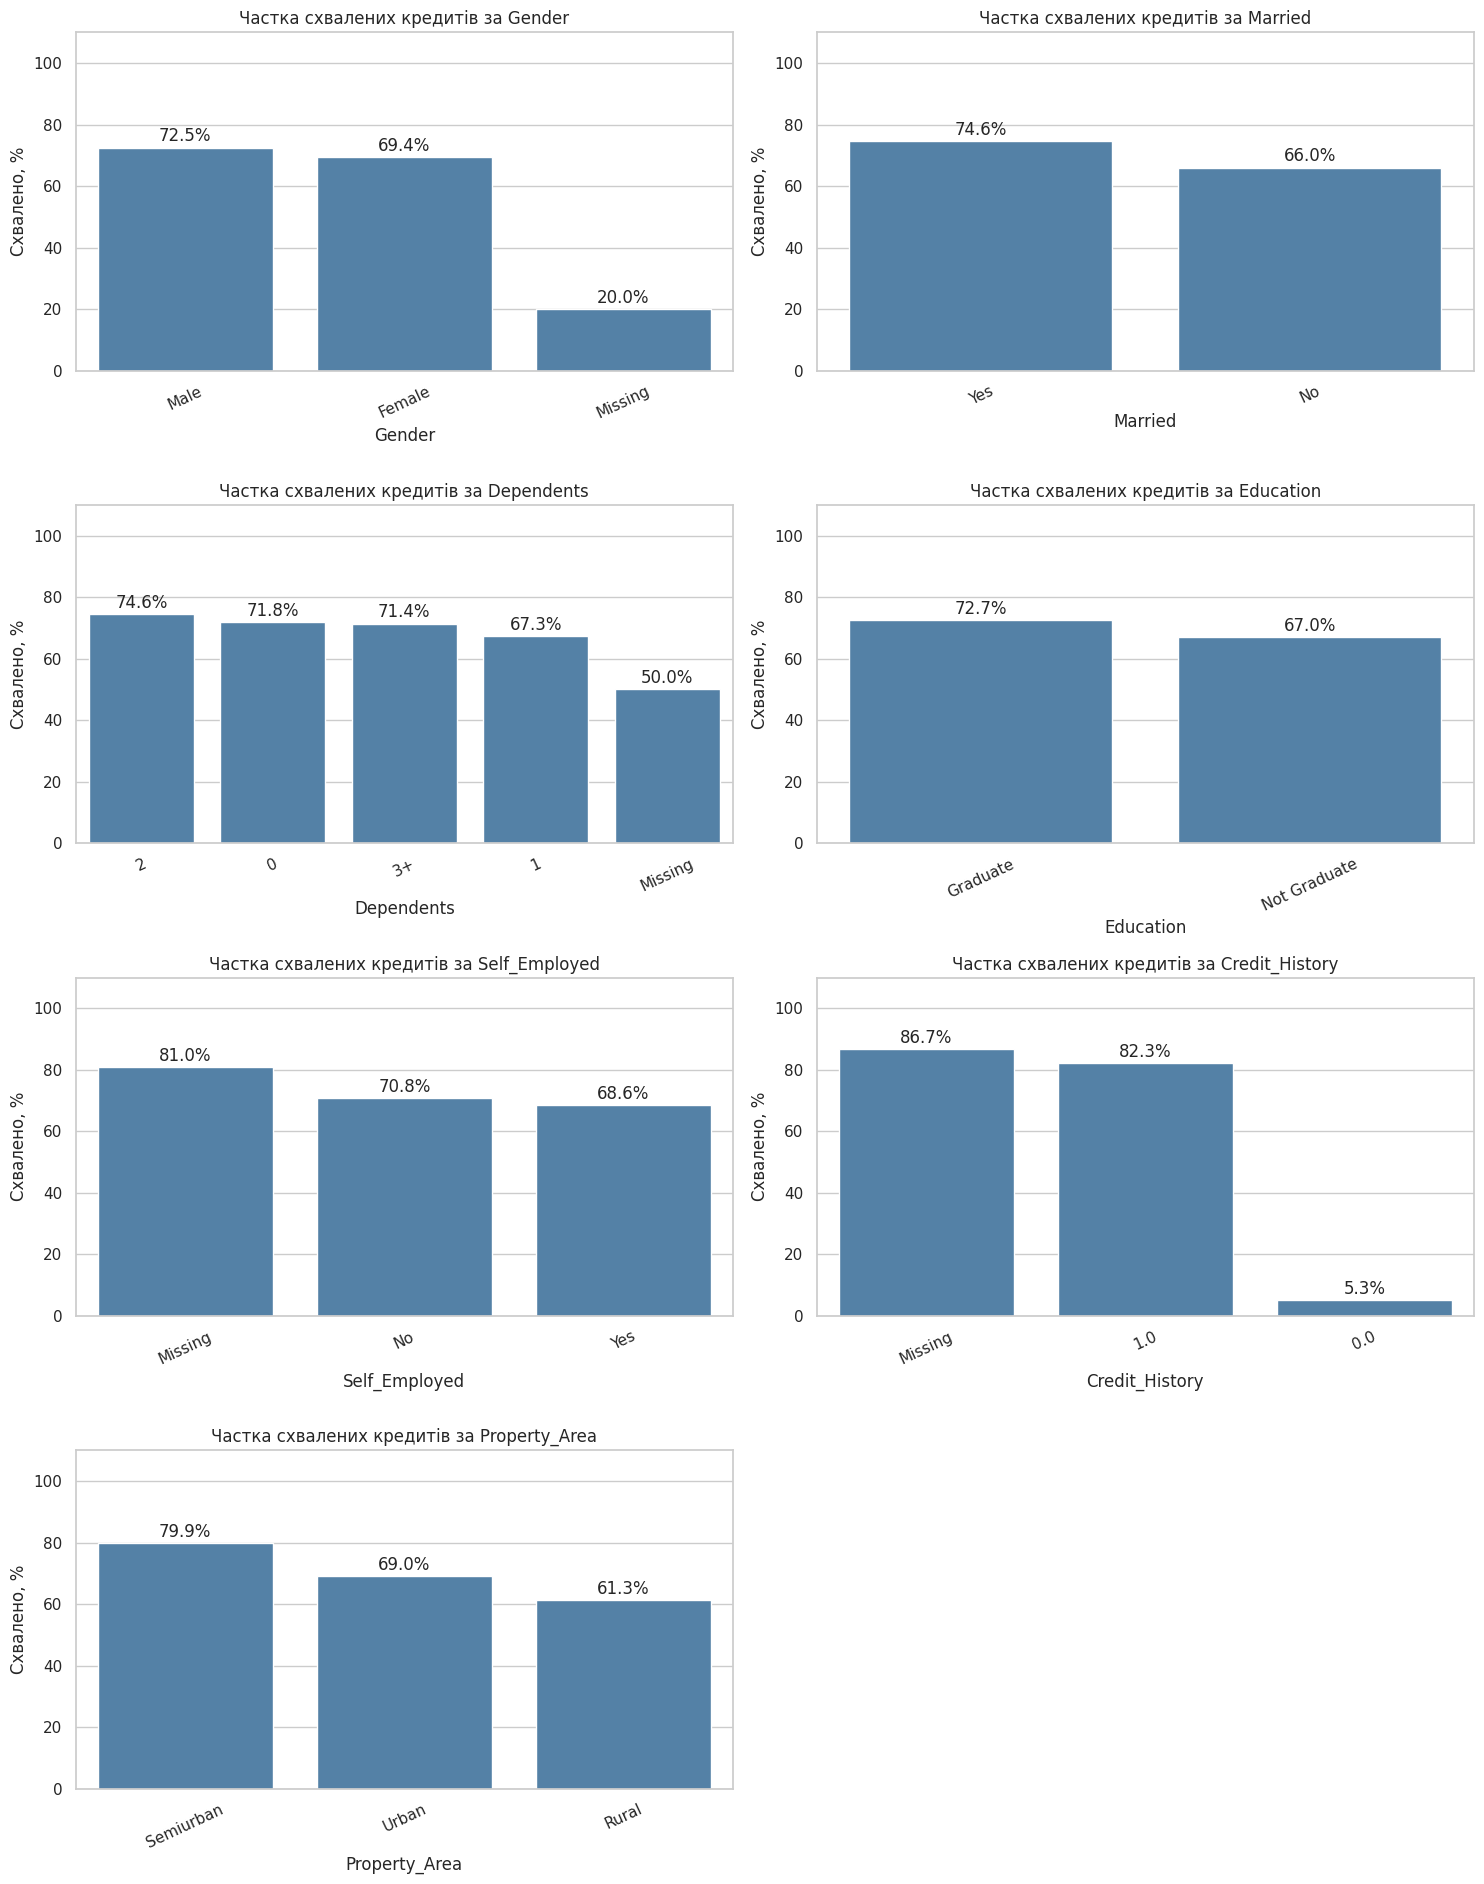


Gender


Loan_Status,N,Y,Всього,"Частка схвалення, %"
Gender,,,,
Female,26,59,85,69.41
Male,80,211,291,72.51
Missing,4,1,5,20.00



Married


Loan_Status,N,Y,Всього,"Частка схвалення, %"
Married,,,,
No,52,101,153,66.01
Yes,58,170,228,74.56



Dependents


Loan_Status,N,Y,Всього,"Частка схвалення, %"
Dependents,,,,
0,66,168,234,71.79
1,17,35,52,67.31
2,15,44,59,74.58
3+,8,20,28,71.43
Missing,4,4,8,50.00


... (4 outputs left out)


Credit_History


Loan_Status,N,Y,Всього,"Частка схвалення, %"
Credit_History,,,,
0.0,54,3,57,5.26
1.0,52,242,294,82.31
Missing,4,26,30,86.67



Property_Area


Loan_Status,N,Y,Всього,"Частка схвалення, %"
Property_Area,,,,
Rural,41,65,106,61.32
Semiurban,30,119,149,79.87
Urban,39,87,126,69.05


In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(15, 19))
axes = axes.flatten()

for i, column in enumerate(categorical_cols):

    temp = df[[column, "Loan_Status"]].copy()
    temp[column] = temp[column].fillna("Missing").astype(str)

    approval_rate = (
        temp.groupby(column)["Loan_Status"]
        .apply(lambda x: (x == "Y").mean() * 100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=approval_rate.index,
        y=approval_rate.values,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(
        f"Частка схвалених кредитів за {column}"
    )
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Схвалено, %")
    axes[i].set_ylim(0, 110)
    axes[i].tick_params(axis="x", rotation=25)

    for j, value in enumerate(approval_rate.values):
        axes[i].text(
            j,
            value + 2,
            f"{value:.1f}%",
            ha="center"
        )

axes[-1].axis("off")

plt.tight_layout()
plt.show()

for column in categorical_cols:

    print(f"\n{column}")

    temp = df[[column, "Loan_Status"]].copy()
    temp[column] = temp[column].fillna("Missing").astype(str)

    summary = pd.crosstab(
        temp[column],
        temp["Loan_Status"]
    )

    summary = summary.reindex(
        columns=["N", "Y"],
        fill_value=0
    )

    summary["Всього"] = summary["N"] + summary["Y"]

    summary["Частка схвалення, %"] = (
        summary["Y"] / summary["Всього"] * 100
    ).round(2)

    display(summary)


Найбільш виражений зв'язок із рішенням щодо кредиту спостерігається для Credit_History. Серед заявників зі значенням кредитної історії 1 схвалено 82,31% заявок (242 із 294), тоді як серед заявників зі значенням 0 — лише 5,26% (3 із 57). Різниця становить 77,05 відсоткового пункта. Це дає підстави розглядати Credit_History як одну з найбільш перспективних ознак для прогнозування Loan_Status. Суттєві відмінності також виявлено за ознакою Property_Area. Найвища частка схвалення спостерігається для Semiurban (79,87%), нижча — для Urban (69,05%) та Rural (61,32%). Також певні відмінності спостерігаються для Married та Education.
Водночас виявлені закономірності характеризують статистичні асоціації, а не причинно-наслідкові залежності.
Наступним етапом дослідження є виявлення зв'язоку числових змінних із прогнозованою змінною Loan_Status.


Ознака: ApplicantIncome


,count,mean,median,std,min,max
Loan_Status,,,,,,
N,110,3602.47,3418.0,1373.65,150,7660
Y,271,3570.66,3276.0,1440.52,210,9703



Ознака: CoapplicantIncome


,count,mean,median,std,min,max
Loan_Status,,,,,,
N,110,1244.19,0.0,3413.91,0.0,33837.0
Y,271,1290.70,1210.0,1733.81,0.0,20000.0



Ознака: LoanAmount


,count,mean,median,std,min,max
Loan_Status,,,,,,
N,110,103.15,106.0,27.68,9.0,150.0
Y,271,105.73,111.0,28.65,17.0,150.0



Ознака: Loan_Amount_Term


,count,mean,median,std,min,max
Loan_Status,,,,,,
N,105,346.06,360.0,70.72,36.0,480.0
Y,265,338.81,360.0,67.70,12.0,480.0


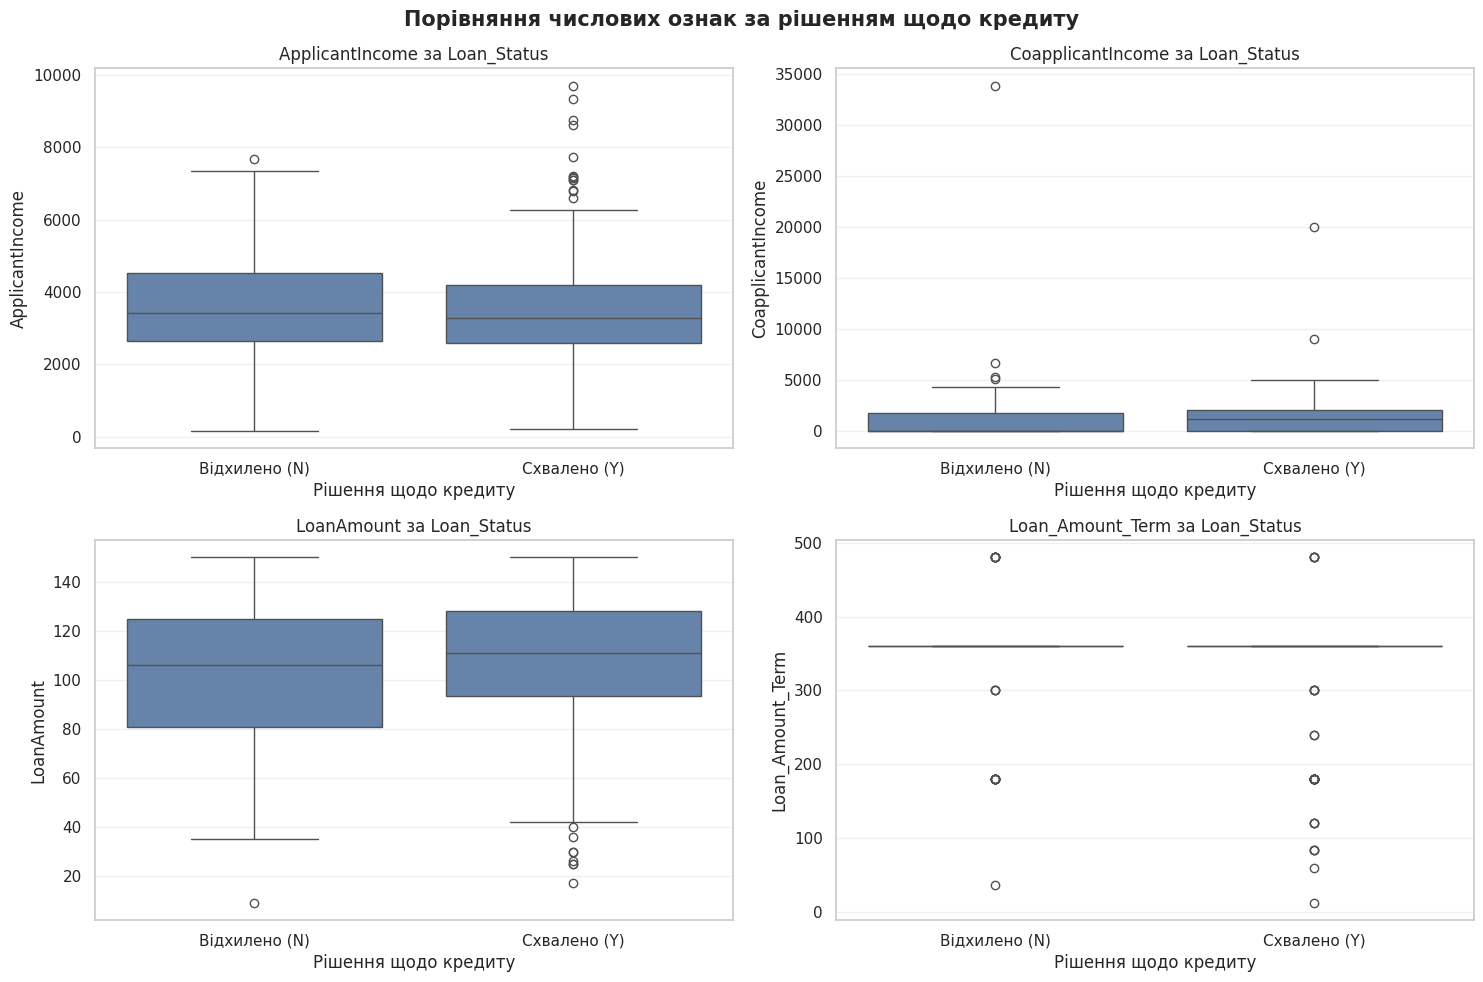

In [ ]:
# Аналіз числових ознак залежно від Loan_Status

numeric_features = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term"
]

# Описова статистика за групами
for feature in numeric_features:
    print(f"\n{'=' * 65}")
    print(f"Ознака: {feature}")
    print(f"{'=' * 65}")

    stats = (
        df.groupby("Loan_Status")[feature]
        .agg(
            count="count",
            mean="mean",
            median="median",
            std="std",
            min="min",
            max="max"
        )
        .round(2)
    )

    display(stats)


# Boxplot числових ознак за Loan_Status
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes = axes.flatten()

for ax, feature in zip(axes, numeric_features):

    sns.boxplot(
        data=df,
        x="Loan_Status",
        y=feature,
        order=["N", "Y"],
        color="#5B83B4",
        ax=ax
    )

    ax.set_title(f"{feature} за Loan_Status", fontsize=12)
    ax.set_xlabel("Рішення щодо кредиту")
    ax.set_ylabel(feature)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Відхилено (N)", "Схвалено (Y)"])
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Порівняння числових ознак за рішенням щодо кредиту",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

ApplicantIncome. Середній дохід заявників зі схваленими кредитами становить 3570,66, а з відхиленими — 3602,47. Медіанні значення дорівнюють 3276 та 3418 відповідно. Отже, суттєвих відмінностей у рівні особистого доходу між групами не виявлено.
CoapplicantIncome. Середній дохід співзаявника становить 1290,70 у групі схвалених кредитів проти 1244,19 у групі відхилених. Водночас медіана суттєво відрізняється: 1210 проти 0. Це може свідчити про потенційний зв'язок доходу співзаявника з рішенням щодо кредитування. Розподіл характеризується значною правосторонньою асиметрією та наявністю екстремальних значень.
LoanAmount. Середня сума схвалених кредитних заявок становить 105,73, а відхилених — 103,15. Медіани дорівнюють 111 та 106 відповідно. Відмінності незначні, а розподіли суттєво перекриваються.
Loan_Amount_Term. Медіанний термін кредитування в обох групах становить 360 місяців. Середні значення дорівнюють 338,81 для схвалених та 346,06 для відхилених заявок. Більшість кредитів мають стандартний термін 360 місяців.
Загалом на основі описових статистик і boxplot не виявлено чіткого розмежування схвалених та відхилених кредитних заявок за більшістю числових ознак. Найпомітніша відмінність спостерігається для медіанного доходу співзаявника.
Наступним логічним кроком EDA буде дослідження кореляцій між числовими змінними та їхнього зв'язку з Loan_Status.

Кореляційна матриця числових ознак:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Loan_Status
ApplicantIncome,1.000,-0.249,0.271,-0.110,-0.010
CoapplicantIncome,-0.249,1.000,0.115,0.002,0.009
LoanAmount,0.271,0.115,1.000,0.124,0.041
Loan_Amount_Term,-0.110,0.002,0.124,1.000,-0.048
Loan_Status,-0.010,0.009,0.041,-0.048,1.000


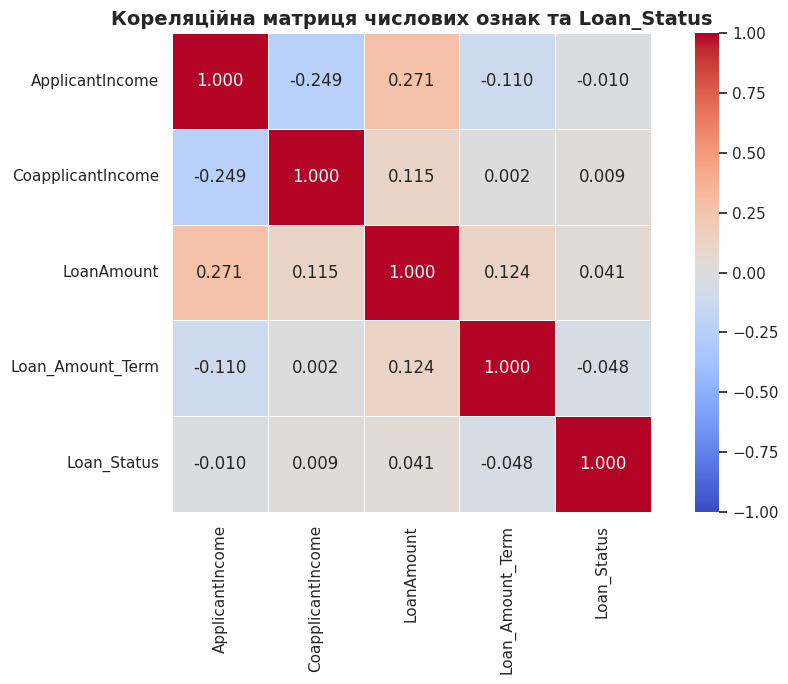


Кореляція числових ознак із Loan_Status:


,Кореляція з Loan_Status,Абсолютна кореляція
Loan_Amount_Term,-0.048,0.048
LoanAmount,0.041,0.041
ApplicantIncome,-0.010,0.010
CoapplicantIncome,0.009,0.009


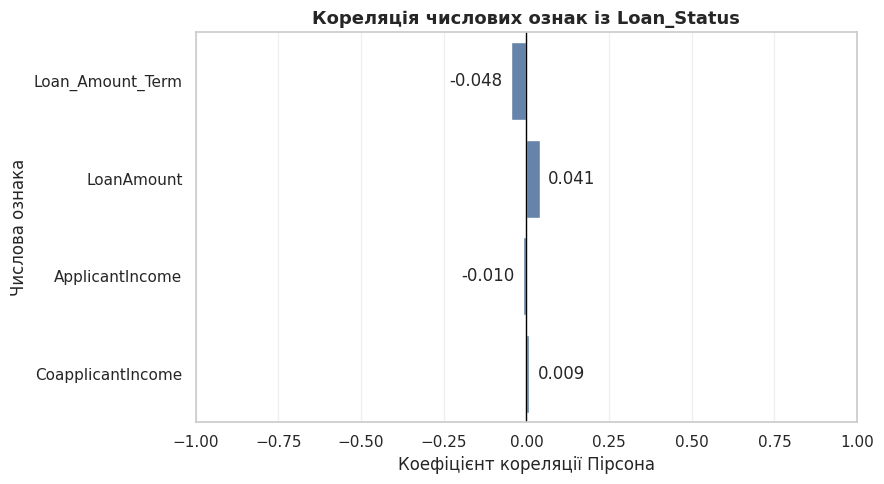

In [ ]:
# Кореляційний аналіз числових ознак

numeric_features = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term"
]

# Створюємо окрему таблицю для кореляційного аналізу.

corr_df = df[numeric_features + ["Loan_Status"]].copy()

# Кодування цільової змінної
corr_df["Loan_Status"] = corr_df["Loan_Status"].map({
    "N": 0,
    "Y": 1
})

# Кореляційна матриця Пірсона
corr_matrix = corr_df.corr(method="pearson")

print("Кореляційна матриця числових ознак:")
display(corr_matrix.round(3))


# Теплова карта кореляцій
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title(
    "Кореляційна матриця числових ознак та Loan_Status",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# Кореляція числових ознак із цільовою змінною
target_corr = (
    corr_matrix["Loan_Status"]
    .drop("Loan_Status")
    .sort_values(key=abs, ascending=False)
)

target_corr_table = pd.DataFrame({
    "Кореляція з Loan_Status": target_corr,
    "Абсолютна кореляція": target_corr.abs()
}).round(3)

print("\nКореляція числових ознак із Loan_Status:")
display(target_corr_table)


# Візуалізація кореляцій із цільовою змінною
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=target_corr.values,
    y=target_corr.index,
    color="#5B83B4"
)

ax.axvline(0, color="black", linewidth=1)

ax.set_title(
    "Кореляція числових ознак із Loan_Status",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Коефіцієнт кореляції Пірсона")
ax.set_ylabel("Числова ознака")

ax.set_xlim(-1, 1)
ax.grid(axis="x", alpha=0.3)

for i, value in enumerate(target_corr.values):
    offset = 0.025 if value >= 0 else -0.025

    ax.text(
        value + offset,
        i,
        f"{value:.3f}",
        va="center",
        ha="left" if value >= 0 else "right"
    )

plt.tight_layout()
plt.show()


Взаємозв'язки між числовими ознаками. Найбільша додатна кореляція спостерігається між ApplicantIncome та LoanAmount (r = 0,271), що свідчить про слабкий прямий лінійний зв'язок між доходом заявника та сумою запитуваного кредиту. Найбільша від'ємна кореляція виявлена між ApplicantIncome та CoapplicantIncome (r = −0,249). Інші парні коефіцієнти перебувають у межах від −0,110 до +0,124.
Оскільки найбільший абсолютний парний коефіцієнт кореляції між числовими предикторами становить 0,271, ознак сильної парної мультиколінеарності не виявлено.Отримані результати свідчать про відсутність виражених лінійних зв'язків між досліджуваними числовими характеристиками та рішенням про схвалення кредиту. Водночас низькі значення кореляції не виключають нелінійних залежностей або взаємодії числових ознак із категоріальними.
Наступним етапом EDA здійснимо аналіз зв'язку між доходом заявника, доходом співзаявника та сумою кредиту та створимо додаткові аналітичні показники TotalIncome (сукупний дохід) і LoanIncomeRatio (відношення суми кредиту до сукупного доходу) і перевіримо їхні розподіли та зв'язок зі схваленням кредиту.

In [ ]:
# Створення нових аналітичних показників

df["TotalIncome"] = (
    df["ApplicantIncome"] + df["CoapplicantIncome"]
)

df["LoanIncomeRatio"] = (
    df["LoanAmount"] / df["TotalIncome"].replace(0, np.nan)
)

new_features = ["TotalIncome", "LoanIncomeRatio"]

print("Описова статистика нових ознак:")

display(
    df[new_features]
    .describe()
    .round(3)
)

print("\nКількість пропущених значень:")

display(
    df[new_features].isna().sum().to_frame("Пропуски")
)

# Розподіл нових показників

alpha = 0.05

shapiro_results = []

for col in new_features:
    values = df[col].dropna()

    w_stat, p_value = shapiro(values)

    shapiro_results.append({
        "Ознака": col,
        "Кількість": len(values),
        "W Шапіро–Вілка": w_stat,
        "p-value": p_value,
        "Рішення": (
            "Відхиляємо H0"
            if p_value < alpha
            else "Не відхиляємо H0"
        ),
        "Висновок": (
            "Розподіл відрізняється від нормального"
            if p_value < alpha
            else "Немає підстав відхиляти нормальність"
        )
    })

shapiro_additional_df = pd.DataFrame(shapiro_results)

display(
    shapiro_additional_df.style.format({
        "W Шапіро–Вілка": "{:.4f}",
        "p-value": "{:.6e}"
    })
)

results = []

for feature in new_features:

    group_y = df.loc[
        df["Loan_Status"] == "Y", feature
    ].dropna()

    group_n = df.loc[
        df["Loan_Status"] == "N", feature
    ].dropna()

    # Двосторонній критерій Манна–Уітні
    u_stat, p_value = mannwhitneyu(
        group_y,
        group_n,
        alternative="two-sided",
        method="auto"
    )

    decision = (
        "Відхиляємо H0"
        if p_value < 0.05
        else "Не відхиляємо H0"
    )

    results.append({
        "Ознака": feature,
        "Медіана Y": group_y.median(),
        "Медіана N": group_n.median(),
        "U Манна–Уітні": u_stat,
        "p-value": p_value,
        "Рішення": decision
    })

mann_new_results = pd.DataFrame(results)

display(
    mann_new_results.style.format({
        "Медіана Y": "{:.3f}",
        "Медіана N": "{:.3f}",
        "U Манна–Уітні": "{:.1f}",
        "p-value": "{:.6g}",
    })
)

Описова статистика нових ознак:


,TotalIncome,LoanIncomeRatio
count,381.000,381.000
mean,4857.121,0.023
std,2417.070,0.007
min,1442.000,0.003
25%,3664.000,0.019
50%,4600.000,0.024
75%,5500.000,0.028
max,35673.000,0.069



Кількість пропущених значень:


,Пропуски
TotalIncome,0
LoanIncomeRatio,0


,Ознака,Кількість,W Шапіро–Вілка,p-value,Рішення,Висновок
0,TotalIncome,381,0.5910,5.537561e-29,Відхиляємо H0,Розподіл відрізняється від нормального
1,LoanIncomeRatio,381,0.9542,1.664468e-09,Відхиляємо H0,Розподіл відрізняється від нормального


,Ознака,Медіана Y,Медіана N,U Манна–Уітні,p-value,Рішення
0,TotalIncome,4600.000,4594.500,16082.5,0.226952,Не відхиляємо H0
1,LoanIncomeRatio,0.024,0.023,14544.0,0.711331,Не відхиляємо H0


За критерієм Шапіро–Вілка обидві додаткові числові ознаки мають статистично значущі відхилення від нормального розподілу. За результатами критерію Манна–Уітні для обох додатково сформованих числових ознак не виявлено статистично значущих відмінностей між групами схвалених та відхилених кредитних заявок.

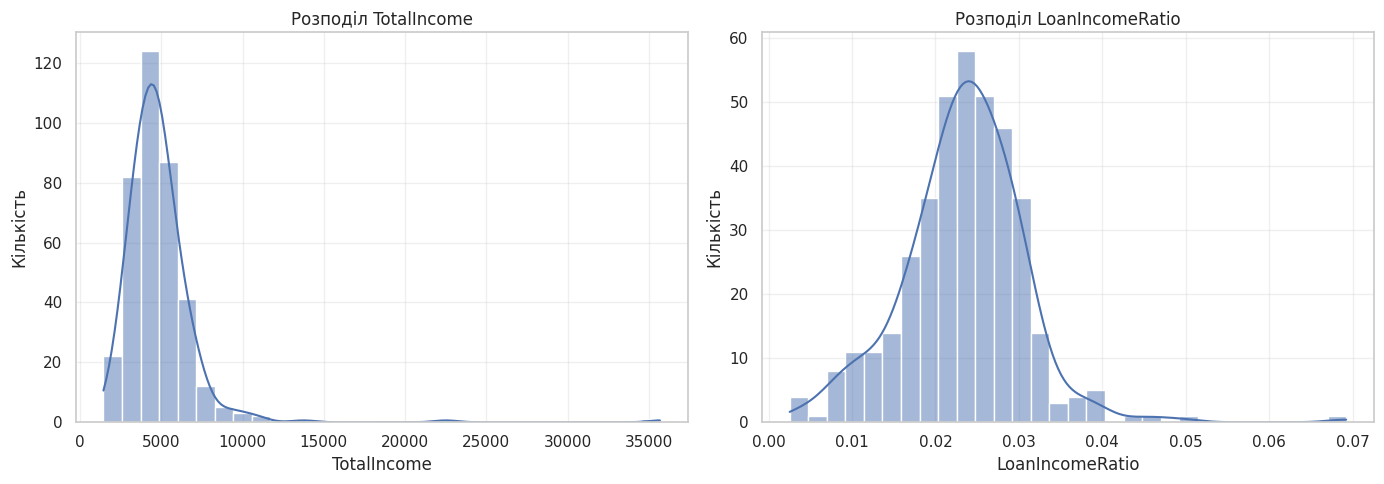


Статистика за Loan_Status:

Ознака: TotalIncome


,count,mean,median,std,min,max
Loan_Status,,,,,,
N,110,4846.664,4594.5,3376.515,1442.0,35673.0
Y,271,4861.365,4600.0,1902.567,1963.0,22500.0



Ознака: LoanIncomeRatio


,count,mean,median,std,min,max
Loan_Status,,,,,,
N,110,0.024,0.023,0.009,0.003,0.069
Y,271,0.023,0.024,0.007,0.004,0.044


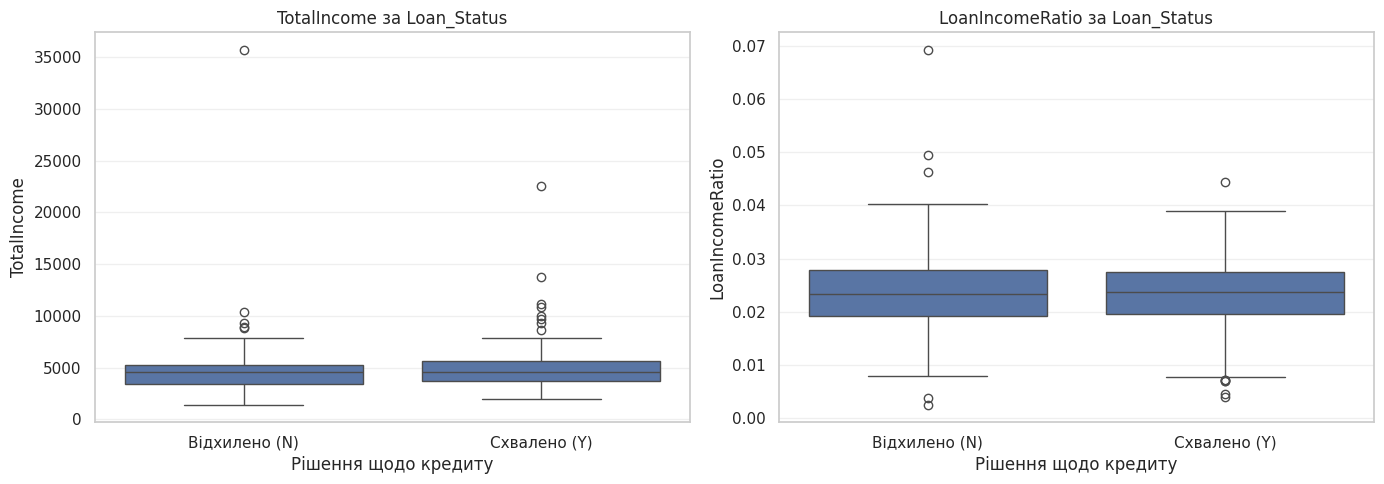


Кореляційна матриця:


,ApplicantIncome,CoapplicantIncome,LoanAmount,TotalIncome,LoanIncomeRatio,Loan_Status
ApplicantIncome,1.000,-0.249,0.271,0.347,-0.324,-0.010
CoapplicantIncome,-0.249,1.000,0.115,0.822,-0.300,0.009
LoanAmount,0.271,0.115,1.000,0.270,0.424,0.041
TotalIncome,0.347,0.822,0.270,1.000,-0.481,0.003
LoanIncomeRatio,-0.324,-0.300,0.424,-0.481,1.000,-0.069
Loan_Status,-0.010,0.009,0.041,0.003,-0.069,1.000



Кореляція з Loan_Status:


,Кореляція з Loan_Status
LoanIncomeRatio,-0.069
LoanAmount,0.041
ApplicantIncome,-0.010
CoapplicantIncome,0.009
TotalIncome,0.003


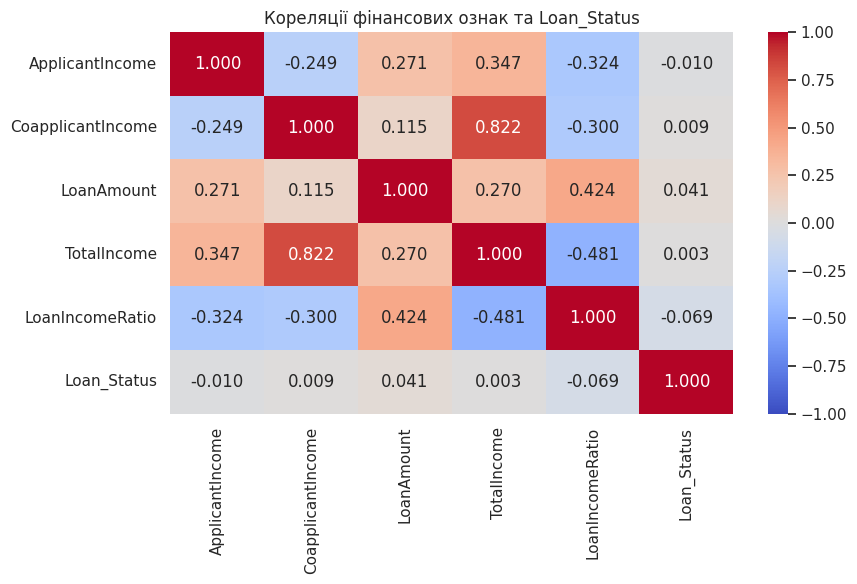

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, new_features):

    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Розподіл {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Кількість")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Порівняння за рішенням щодо кредиту

print("\nСтатистика за Loan_Status:")

for col in new_features:

    print(f"\nОзнака: {col}")

    stats = (
        df.groupby("Loan_Status")[col]
        .agg(
            count="count",
            mean="mean",
            median="median",
            std="std",
            min="min",
            max="max"
        )
        .round(3)
    )

    display(stats)


# Boxplot нових ознак за Loan_Status

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, new_features):

    sns.boxplot(
        data=df,
        x="Loan_Status",
        y=col,
        order=["N", "Y"],
        ax=ax
    )

    ax.set_title(f"{col} за Loan_Status")
    ax.set_xlabel("Рішення щодо кредиту")
    ax.set_ylabel(col)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Відхилено (N)", "Схвалено (Y)"])
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Кореляція нових ознак із Loan_Status

df_corr = df[
    [
        "ApplicantIncome",
        "CoapplicantIncome",
        "LoanAmount",
        "TotalIncome",
        "LoanIncomeRatio"
    ]
].copy()

df_corr["Loan_Status"] = (
    df["Loan_Status"].map({"N": 0, "Y": 1})
)

corr_matrix = df_corr.corr()

print("\nКореляційна матриця:")
display(corr_matrix.round(3))

print("\nКореляція з Loan_Status:")

target_corr = (
    corr_matrix["Loan_Status"]
    .drop("Loan_Status")
    .sort_values(key=abs, ascending=False)
)

display(
    target_corr.to_frame("Кореляція з Loan_Status").round(3)
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Кореляції фінансових ознак та Loan_Status")
plt.tight_layout()
plt.show()


Кореляційний аналіз засвідчив, що нові фінансові ознаки мають дуже слабкий лінійний зв'язок із рішенням щодо кредиту. Для TotalIncome коефіцієнт кореляції становить 0,003, а для LoanIncomeRatio — −0,069. Останній показник має найбільший за абсолютною величиною зв'язок із цільовою змінною серед розглянутих фінансових характеристик, проте його величина залишається низькою.
Проте помітно, що TotalIncome має дуже високе значення коефіцієнта парної кореляції з CoapplicantIncome	та LoanIncomeRatio, що логічно є фактором наявності мультиколінеарності.
Вище було доведено, що за критерієм Манна-Уітні статистично значущі відмінності встановлено лише для доходу співзаявника CoapplicantIncome у групах схвалених і відхилених кредитів, тому цю змінну виключати не доцільно. Тому з подальшого розгляду виключимо нову розрахункову змінну TotalIncome.
Наступним етапом EDA є перевірка зв'язку між категоріальними предикторами та Loan_Status за критерієм χ² Пірсона та V Крамера.

In [ ]:
from scipy.stats import chi2_contingency

alpha = 0.05

categorical_features = [
    "Gender",
    "Married",
    "Dependents",
    "Education",
    "Self_Employed",
    "Credit_History",
    "Property_Area"
]

chi2_results = []

for col in categorical_features:
    # Пропуски розглядаємо як окрему категорію
    feature = df[col].astype("object").fillna("Missing")

    contingency_table = pd.crosstab(
        feature,
        df["Loan_Status"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table,
        correction=False
    )

    # V Крамера
    n = contingency_table.to_numpy().sum()
    r, k = contingency_table.shape

    cramers_v = np.sqrt(
        (chi2 / n) / min(r - 1, k - 1)
    )

    chi2_results.append({
        "Ознака": col,
        "Chi2": chi2,
        "df": dof,
        "p-value": p_value,
        "V Крамера": cramers_v,
        "Очікуваних < 5": (expected < 5).sum(),
        "Рішення": (
            "Відхиляємо H0"
            if p_value < alpha
            else "Не відхиляємо H0"
        )
    })

chi2_df = pd.DataFrame(chi2_results)

chi2_df = chi2_df.sort_values(
    "V Крамера",
    ascending=False
)

display(
    chi2_df.style.format({
        "Chi2": "{:.4f}",
        "p-value": "{:.6g}",
        "V Крамера": "{:.4f}"
    })
)


,Ознака,Chi2,df,p-value,V Крамера,Очікуваних < 5,Рішення
5,Credit_History,141.8496,2,1.57671e-31,0.6102,0,Відхиляємо H0
6,Property_Area,10.7698,2,0.0045854,0.1681,0,Відхиляємо H0
0,Gender,6.7567,2,0.0341041,0.1332,2,Відхиляємо H0
1,Married,3.2580,1,0.0710755,0.0925,0,Не відхиляємо H0
2,Dependents,2.5021,4,0.644265,0.0810,1,Не відхиляємо H0
3,Education,1.1772,1,0.277925,0.0556,0,Не відхиляємо H0
4,Self_Employed,1.1188,2,0.571561,0.0542,0,Не відхиляємо H0


За результатами перевірки статистичної незалежності категоріальних ознак та цільової змінної Loan_Status за критерієм χ² Пірсона встановлено, що на рівні значущості α = 0,05 статистично значущі асоціації спостерігаються для Credit_History (p < 0,001), Property_Area (p = 0,00459) та Gender (p = 0,03410).
Найсильніший зв'язок виявлено для кредитної історії (Credit_History), коефіцієнт V Крамера становить 0,6102. Це підтверджує її високу потенційну інформативність для прогнозування рішення щодо кредиту.
Для Property_Area значення V Крамера становить 0,1681, що свідчить про слабкий, але статистично значущий зв'язок із цільовою змінною.
Таким чином, за результатами аналізу категоріальних ознак найбільшу увагу під час побудови моделей машинного навчання доцільно приділити Credit_History та Property_Area.

Загалом варто зазаначити, що найбільш виражений статистичний зв'язок із рішенням щодо схвалення кредиту встановлено для кредитної історії (Credit_History). Слабші зв'язки виявлено для типу території (Property_Area), статі (Gender) та доходу співзаявника (CoapplicantIncome).
Більшість числових характеристик не продемонстрували статистично значущих відмінностей між групами схвалених і відхилених заявок, що свідчить про обмежену інформативність їхнього окремого використання для пояснення кредитного рішення.

In [ ]:
# Створення папки для результатів
output_dir = Path("data")
output_dir.mkdir(parents=True, exist_ok=True)

# Копія набору даних після EDA
df_export = df.copy()

# Видалення ідентифікатора кредитної заявки та показника TotalIncome
df_export = df_export.drop(columns=["Loan_ID", "TotalIncome"])

# Кодування цільової змінної
# Y — кредит схвалено (1)
# N — кредит відхилено (0)

status_mapping = {
    "Y": 1,
    "N": 0
}

# Підтримка як текстового, так і вже числового формату
if not df_export["Loan_Status"].isin([0, 1]).all():
    df_export["Loan_Status"] = (
        df_export["Loan_Status"].map(status_mapping)
    )

if df_export["Loan_Status"].isna().any():
    raise ValueError(
        "Loan_Status містить невідомі або пропущені значення."
    )

df_export["Loan_Status"] = (
    df_export["Loan_Status"].astype(int)
)

# Збереження даних для машинного навчання
data_path = output_dir / "loan_data_eda.csv"

df_export.to_csv(
    data_path,
    index=False,
    encoding="utf-8-sig"
)

# Контроль результатів
print("Збереження завершено.")
print(f"Дані: {data_path.resolve()}")

print("\nРозмір набору даних:", df_export.shape)

print("\nРозподіл цільової змінної:")
display(
    df_export["Loan_Status"]
    .value_counts()
    .sort_index()
    .rename_axis("Loan_Status")
    .to_frame("Кількість")
)

print("\nПерші 5 рядків підготовлених даних:")
display(df_export.head())


Збереження завершено.
Дані: /content/data/loan_data_eda.csv

Розмір набору даних: (381, 13)

Розподіл цільової змінної:


,Кількість
Loan_Status,
0,110
1,271



Перші 5 рядків підготовлених даних:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,LoanIncomeRatio
0,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,0,0.021015
1,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,1,0.022000
2,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,1,0.024287
3,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,1,0.023500
4,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,1,0.024682
